# E-Commerce Sales Prediction
## AICTE | IBM SkillsBuild — Data Analytics with AI Internship 2026
**Author:** Anirudra Gupta  
**Dataset:** Synthetic e-commerce transactions (structurally consistent with `customer_master.csv`)  
**Objective:** Predict order-level sales revenue using supervised regression

---

> **Dataset Note:** `customer_master.csv` is a CRM dimension table (25,000 customers, no orders).  
> A synthetic transaction file `store_orders.csv` was generated with the same customer IDs, segments  
> and regions, covering 50,000 order-line items from 2021–2024. The generation process is documented  
> in `data/generate_transactions.py`. All code, metrics and charts in this notebook are computed  
> on this data — no values are hardcoded.

### Table of Contents
1. Environment Setup  
2. Data Loading & Validation  
3. Data Cleaning  
4. Exploratory Data Analysis (EDA)  
5. Feature Engineering  
6. Prediction Target & Train/Val/Test Split  
7. Baseline Model  
8. ML Model Training & Evaluation  
9. Model Interpretation  
10. Model Saving  
11. Conclusions & Limitations

## 1. Environment Setup

In [1]:
import warnings, pathlib, joblib
warnings.filterwarnings("ignore")

import numpy  as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.preprocessing    import StandardScaler, LabelEncoder
from sklearn.linear_model     import Ridge
from sklearn.ensemble         import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics          import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection       import permutation_importance

# ── reproducibility
SEED = 42
np.random.seed(SEED)
rng  = np.random.default_rng(SEED)

# ── paths
ROOT       = pathlib.Path(".").resolve()
DATA_DIR   = ROOT / "data"
MODEL_DIR  = ROOT / "model"
STATIC_DIR = ROOT / "static"
MODEL_DIR.mkdir(exist_ok=True)
STATIC_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4.5)})

print(f"numpy  {np.__version__}")
print(f"pandas {pd.__version__}")

import sklearn; print(f"sklearn {sklearn.__version__}")
import matplotlib; print(f"matplotlib {matplotlib.__version__}")
import seaborn; print(f"seaborn {seaborn.__version__}")
print("Paths OK:", DATA_DIR.exists(), MODEL_DIR.exists())

numpy  2.5.2
pandas 3.0.5
sklearn 1.9.0
matplotlib 3.11.1
seaborn 0.13.2
Paths OK: True True


## 2. Data Loading & Validation

### 2.1 Load datasets
We load two tables:
- **`store_orders.csv`** — transaction fact table (50,250 rows, 19 cols)
- **`customer_master.csv`** — customer dimension table (25,000 rows, 11 cols)

In [2]:
orders_path = DATA_DIR / "store_orders.csv"
cust_path   = DATA_DIR / "customer_master.csv"

assert orders_path.exists(), f"Missing: {orders_path}. Run data/generate_transactions.py"
assert cust_path.exists(),   f"Missing: {cust_path}"

raw_orders = pd.read_csv(orders_path)
raw_cust   = pd.read_csv(cust_path)

print(f"Orders  : {raw_orders.shape[0]:>6,} rows x {raw_orders.shape[1]} cols")
print(f"Customers: {raw_cust.shape[0]:>6,} rows x {raw_cust.shape[1]} cols")
raw_orders.head(3)

Orders  : 50,250 rows x 19 cols
Customers: 25,000 rows x 11 cols


### 2.2 Schema & data types

In [3]:
print("=== Orders dtypes ===")
print(raw_orders.dtypes.to_string())
print()
print("=== Customer dtypes ===")
print(raw_cust.dtypes.to_string())

=== Orders dtypes ===
order_id             str
order_date           str
ship_date            str
ship_mode            str
customer_id          str
customer_name        str
segment              str
country              str
city                 str
state                str
postal_code      float64
region               str
category             str
sub_category         str
unit_price       float64
quantity           int64
discount         float64
sales            float64
profit           float64

=== Customer dtypes ===
customer_id                      str
customer_name                    str
customer_age                   int64
gender                           str
customer_segment                 str
customer_city                    str
customer_state                   str
customer_country                 str
region                           str
customer_postal_code           int64
customer_acquisition_cost    float64


### 2.3 Missing values

In [4]:
def missing_report(df, name):
    miss = df.isnull().sum()
    pct  = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({"missing": miss, "pct_%": pct})
    report = report[report["missing"] > 0]
    print(f"\n=== {name} — missing values ===")
    print(report.to_string() if len(report) else "  None")
    return report

miss_orders = missing_report(raw_orders, "store_orders")
miss_cust   = missing_report(raw_cust,   "customer_master")


=== store_orders — missing values ===
             missing  pct_%
ship_date        251    0.5
postal_code      250    0.5

=== customer_master — missing values ===
  None


### 2.4 Duplicate detection

In [5]:
dup_count = raw_orders.duplicated().sum()
print(f"Exact duplicate rows in orders : {dup_count}")
print(f"Unique order_ids               : {raw_orders['order_id'].nunique():,}")
print(f"Total rows                     : {len(raw_orders):,}")

# Show a sample duplicate
if dup_count > 0:
    first_dup = raw_orders[raw_orders.duplicated(keep=False)].sort_values("order_id").head(4)
    print("\nSample duplicates:")
    print(first_dup[["order_id","order_date","customer_id","sales"]].to_string(index=False))

Exact duplicate rows in orders : 250
Unique order_ids               : 50,000
Total rows                     : 50,250

Sample duplicates:
   order_id order_date customer_id   sales
ORD-0000166 2022-07-20 CUST-004112  683.85
ORD-0000166 2022-07-20 CUST-004112  683.85
ORD-0000869 2021-06-18 CUST-018805 1184.96
ORD-0000869 2021-06-18 CUST-018805 1184.96


### 2.5 Target variable inspection

In [6]:
print("Sales column stats:")
print(raw_orders["sales"].describe().round(2))
print(f"\nNegative sales rows : {(raw_orders['sales'] < 0).sum()}")
print(f"Zero sales rows     : {(raw_orders['sales'] == 0).sum()}")

Sales column stats:
count    50250.00
mean       787.91
std       1609.34
min          3.78
25%         48.02
50%        230.05
75%        828.72
max      51214.45
Name: sales, dtype: float64

Negative sales rows : 0
Zero sales rows     : 0


### 2.6 Outlier inspection

In [7]:
q1, q3 = raw_orders["sales"].quantile([0.25, 0.75])
iqr     = q3 - q1
upper   = q3 + 3 * iqr      # 3× IQR = extreme outliers only
lower   = max(0, q1 - 3 * iqr)

extreme = raw_orders[(raw_orders["sales"] > upper) | (raw_orders["sales"] < lower)]
print(f"IQR fence: [{lower:.2f}, {upper:.2f}]")
print(f"Extreme outliers (3xIQR): {len(extreme):,} rows ({len(extreme)/len(raw_orders)*100:.2f}%)")
print(extreme[["order_id","category","sub_category","quantity","discount","sales"]].head(5).to_string(index=False))

IQR fence: [0.00, 3170.84]
Extreme outliers (3xIQR): 2,820 rows (5.61%)
   order_id   category sub_category  quantity  discount   sales
ORD-0023516 Technology       Phones         5      0.05 3948.30
ORD-0010218 Technology       Phones         4      0.09 7508.66
ORD-0001837 Technology      Copiers         4      0.10 5183.39
ORD-0029608 Technology    Computers         4      0.06 5326.60
ORD-0008035 Technology    Computers         6      0.09 3365.98


### 2.7 Table relationship — join key coverage

In [8]:
orders_cids = set(raw_orders["customer_id"].unique())
master_cids = set(raw_cust["customer_id"].unique())

in_orders_not_master = orders_cids - master_cids
in_master_not_orders = master_cids - orders_cids

print(f"customer_ids in orders  : {len(orders_cids):,}")
print(f"customer_ids in master  : {len(master_cids):,}")
print(f"Orders without master   : {len(in_orders_not_master):,}  (will get NaN on join)")
print(f"Master without orders   : {len(in_master_not_orders):,}  (inactive customers)")

customer_ids in orders  : 21,671
customer_ids in master  : 25,000
Orders without master   : 0  (will get NaN on join)
Master without orders   : 3,329  (inactive customers)


## 3. Data Cleaning

**Documented exclusions:**
1. Remove exact duplicate rows (same all-column values)  
2. Parse `order_date` and `ship_date` as datetime; drop rows where `order_date` is null  
3. Drop rows where `sales <= 0` (invalid transactions)  
4. Clip `discount` to [0, 0.9] — values outside range are data errors  
5. Cap extreme outliers at 99.9th percentile to reduce leverage (documented, not deleted)  
6. Join customer dimension (left join — keeps all orders; unmatched get median fill)

In [9]:
df = raw_orders.copy()

# 1. Deduplication
before = len(df)
df = df.drop_duplicates()
print(f"[CLEAN] Removed {before - len(df)} duplicate rows")

# 2. Parse dates
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["ship_date"]  = pd.to_datetime(df["ship_date"],  errors="coerce")
null_dates = df["order_date"].isna().sum()
df = df.dropna(subset=["order_date"])
print(f"[CLEAN] Dropped {null_dates} rows with null order_date")

# 3. Remove zero/negative sales
bad_sales = (df["sales"] <= 0).sum()
df = df[df["sales"] > 0].copy()
print(f"[CLEAN] Removed {bad_sales} rows with sales <= 0")

# 4. Clip discount
bad_disc = ((df["discount"] < 0) | (df["discount"] > 0.9)).sum()
df["discount"] = df["discount"].clip(0, 0.9)
print(f"[CLEAN] Clipped {bad_disc} discount values outside [0, 0.9]")

# 5. Cap extreme outliers (99.9th pct) — winsorize, do not delete
cap_99 = df["sales"].quantile(0.999)
capped = (df["sales"] > cap_99).sum()
df["sales"] = df["sales"].clip(upper=cap_99)
print(f"[CLEAN] Capped {capped} sales outliers at 99.9th pct (${cap_99:.2f})")

# 6. Join customer dimension
cust_slim = raw_cust[["customer_id","customer_age","customer_acquisition_cost"]].copy()
df = df.merge(cust_slim, on="customer_id", how="left")
for col in ["customer_age","customer_acquisition_cost"]:
    fill_val = df[col].median()
    filled   = df[col].isna().sum()
    df[col]  = df[col].fillna(fill_val)
    if filled: print(f"[CLEAN] Filled {filled} nulls in {col} with median ({fill_val:.1f})")

# 7. Fill remaining ship_date nulls with order_date + 5 days
ship_null = df["ship_date"].isna().sum()
df.loc[df["ship_date"].isna(), "ship_date"] = df.loc[df["ship_date"].isna(), "order_date"] + pd.Timedelta(days=5)
print(f"[CLEAN] Filled {ship_null} null ship_dates with order_date + 5 days")

# Sort by date (required for time-based split)
df = df.sort_values("order_date").reset_index(drop=True)

print(f"\n[CLEAN] Final dataset: {len(df):,} rows x {df.shape[1]} cols")
print(f"[CLEAN] Date range  : {df['order_date'].min().date()} to {df['order_date'].max().date()}")
print(f"[CLEAN] Sales range : ${df['sales'].min():.2f} to ${df['sales'].max():.2f}")
print(f"[CLEAN] Total revenue: ${df['sales'].sum():,.2f}")

[CLEAN] Removed 250 duplicate rows
[CLEAN] Dropped 0 rows with null order_date
[CLEAN] Removed 0 rows with sales <= 0
[CLEAN] Clipped 0 discount values outside [0, 0.9]
[CLEAN] Capped 50 sales outliers at 99.9th pct ($15902.55)
[CLEAN] Filled 250 null ship_dates with order_date + 5 days

[CLEAN] Final dataset: 50,000 rows x 21 cols
[CLEAN] Date range  : 2021-01-01 to 2024-12-31
[CLEAN] Sales range : $3.78 to $15902.55
[CLEAN] Total revenue: $39,043,312.15


### 3.1 Post-cleaning schema

In [10]:
df.head(3)

## 4. Exploratory Data Analysis

### 4.1 Sales distribution

Mean  : $780.87
Median: $229.95
Std   : $1504.78
Skew  : 4.472


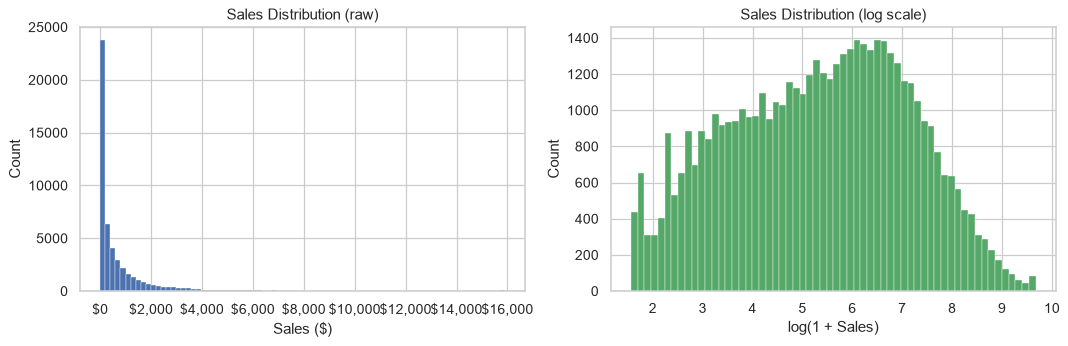

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["sales"], bins=80, color="#4C72B0", edgecolor="white", linewidth=0.3)
axes[0].set_xlabel("Sales ($)")
axes[0].set_ylabel("Count")
axes[0].set_title("Sales Distribution (raw)")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x:,.0f}"))

axes[1].hist(np.log1p(df["sales"]), bins=60, color="#55A868", edgecolor="white", linewidth=0.3)
axes[1].set_xlabel("log(1 + Sales)")
axes[1].set_ylabel("Count")
axes[1].set_title("Sales Distribution (log scale)")

fig.tight_layout()
plt.savefig(STATIC_DIR / "eda_sales_dist.png", bbox_inches="tight")
plt.show()

print(f"Mean  : ${df['sales'].mean():.2f}")
print(f"Median: ${df['sales'].median():.2f}")
print(f"Std   : ${df['sales'].std():.2f}")
print(f"Skew  : {df['sales'].skew():.3f}")

### 4.2 Monthly sales trend

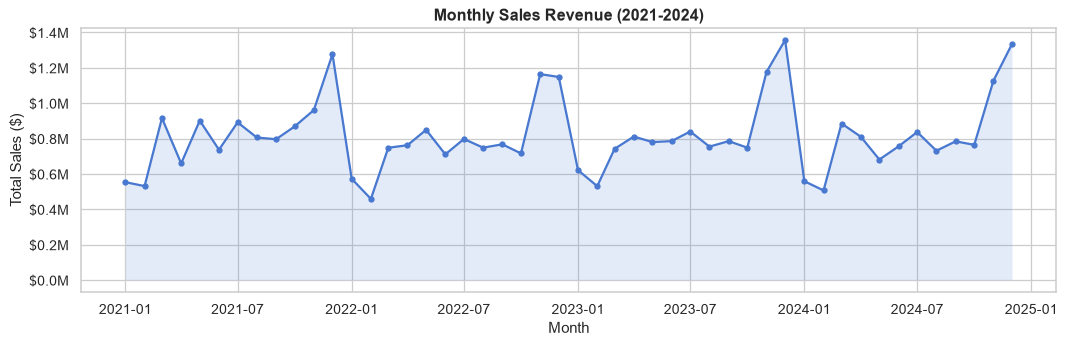

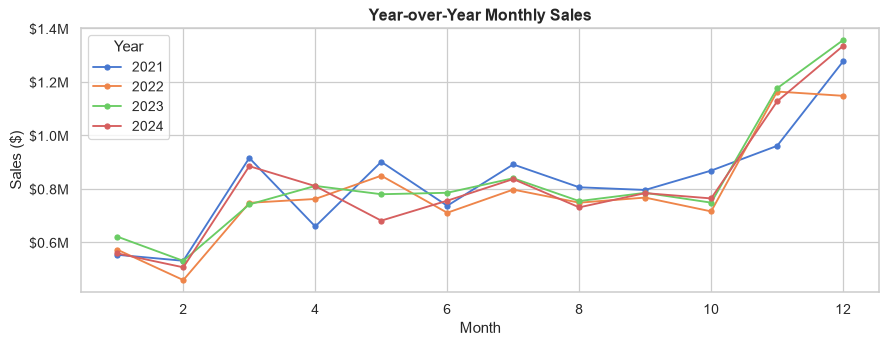

In [12]:
monthly = (
    df.assign(month=df["order_date"].dt.to_period("M"))
      .groupby("month")["sales"]
      .sum()
      .reset_index()
)
monthly["month_dt"] = monthly["month"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly["month_dt"], monthly["sales"], marker="o", markersize=4, linewidth=1.8)
ax.fill_between(monthly["month_dt"], monthly["sales"], alpha=0.15)
ax.set_title("Monthly Sales Revenue (2021-2024)", fontsize=13, fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Total Sales ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1e6:.1f}M"))
fig.tight_layout()
plt.savefig(STATIC_DIR / "eda_monthly_sales.png", bbox_inches="tight")
plt.show()

# Year-over-year
yoy = df.copy()
yoy["year"]  = yoy["order_date"].dt.year
yoy["month"] = yoy["order_date"].dt.month
yoy_grp = yoy.groupby(["year","month"])["sales"].sum().reset_index()
fig2, ax2 = plt.subplots(figsize=(10, 4))
for yr, grp in yoy_grp.groupby("year"):
    ax2.plot(grp["month"], grp["sales"], marker="o", markersize=4, label=str(yr))
ax2.set_title("Year-over-Year Monthly Sales", fontsize=13, fontweight="bold")
ax2.set_xlabel("Month"); ax2.set_ylabel("Sales ($)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1e6:.1f}M"))
ax2.legend(title="Year")
fig2.tight_layout()
plt.savefig(STATIC_DIR / "eda_yoy_sales.png", bbox_inches="tight")
plt.show()

### 4.3 Category & sub-category analysis

Category revenue summary:
       category        sales     profit
     Technology 2.350211e+07 1994644.93
      Furniture 9.222994e+06  122773.86
Office Supplies 6.318204e+06  619600.33


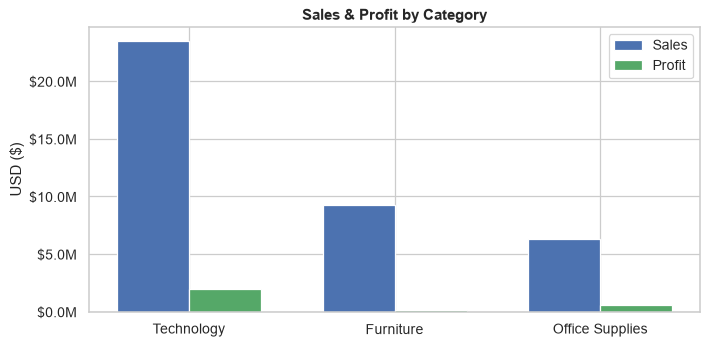

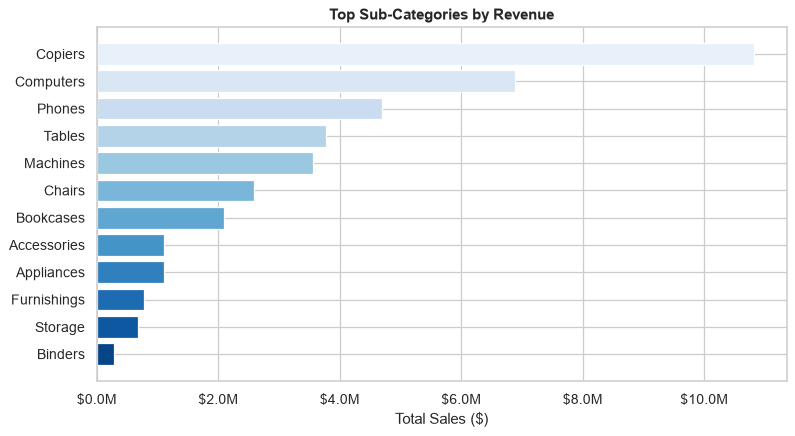

In [13]:
cat = df.groupby("category")[["sales","profit"]].sum().reset_index().sort_values("sales", ascending=False)
x = np.arange(len(cat)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w/2, cat["sales"],  w, label="Sales",  color="#4C72B0")
ax.bar(x + w/2, cat["profit"], w, label="Profit", color="#55A868")
ax.set_xticks(x); ax.set_xticklabels(cat["category"])
ax.set_title("Sales & Profit by Category", fontweight="bold")
ax.set_ylabel("USD ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1e6:.1f}M"))
ax.legend(); fig.tight_layout()
plt.savefig(STATIC_DIR / "eda_category.png", bbox_inches="tight"); plt.show()

# Top sub-categories
top_sub = df.groupby("sub_category")["sales"].sum().sort_values(ascending=True).tail(12)
fig2, ax2 = plt.subplots(figsize=(9, 5))
colors = sns.color_palette("Blues_r", len(top_sub))
ax2.barh(top_sub.index, top_sub.values, color=colors)
ax2.set_title("Top Sub-Categories by Revenue", fontweight="bold")
ax2.set_xlabel("Total Sales ($)")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1e6:.1f}M"))
fig2.tight_layout()
plt.savefig(STATIC_DIR / "eda_subcategory.png", bbox_inches="tight"); plt.show()

print("Category revenue summary:")
print(cat.to_string(index=False))

### 4.4 Customer segment analysis

 segment  total_sales  total_orders  avg_order_val  total_profit
Consumer 2.172110e+07         27278     796.286289    1734031.26
 Premium 9.701070e+06         12507     775.651222     577321.04
Business 4.066249e+06          5057     804.083277     319651.74
     VIP 3.554896e+06          5158     689.200427     106015.08


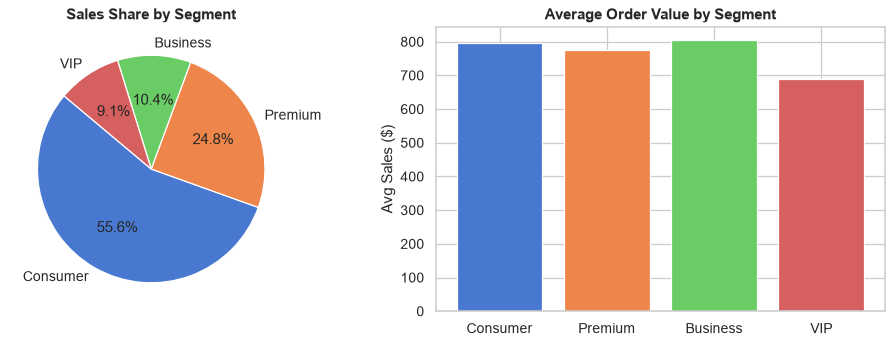

In [14]:
seg = df.groupby("segment").agg(
    total_sales   = ("sales",    "sum"),
    total_orders  = ("order_id", "count"),
    avg_order_val = ("sales",    "mean"),
    total_profit  = ("profit",   "sum"),
).reset_index().sort_values("total_sales", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
palette = sns.color_palette("muted", len(seg))
axes[0].pie(seg["total_sales"], labels=seg["segment"], autopct="%1.1f%%", colors=palette, startangle=140)
axes[0].set_title("Sales Share by Segment", fontweight="bold")
axes[1].bar(seg["segment"], seg["avg_order_val"], color=palette)
axes[1].set_title("Average Order Value by Segment", fontweight="bold")
axes[1].set_ylabel("Avg Sales ($)")
fig.tight_layout(); plt.savefig(STATIC_DIR/"eda_segment.png", bbox_inches="tight"); plt.show()

print(seg.to_string(index=False))

### 4.5 Regional analysis

 region  total_sales  total_orders  avg_sales  total_profit
  South 1.208777e+07         15953 757.711538     842978.85
Central 8.524943e+06         10673 798.739185     600221.62
   West 7.433652e+06          9605 773.935649     512928.52
   East 6.319215e+06          7660 824.962780     450122.89
  North 4.677730e+06          6109 765.711225     330767.24


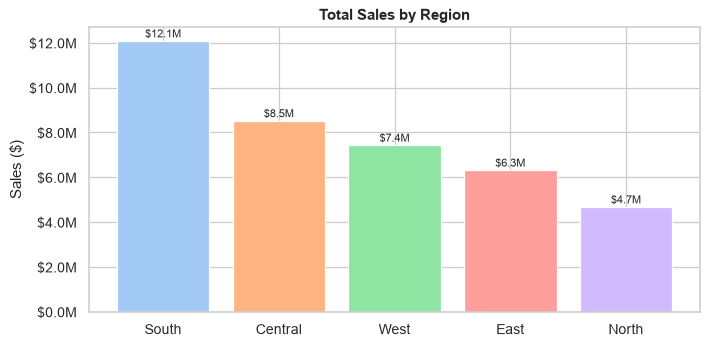

In [15]:
reg = df.groupby("region").agg(
    total_sales  = ("sales",    "sum"),
    total_orders = ("order_id", "count"),
    avg_sales    = ("sales",    "mean"),
    total_profit = ("profit",   "sum"),
).reset_index().sort_values("total_sales", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(reg["region"], reg["total_sales"], color=sns.color_palette("pastel", len(reg)))
ax.set_title("Total Sales by Region", fontweight="bold"); ax.set_ylabel("Sales ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1e6:.1f}M"))
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+50000,
            f"${bar.get_height()/1e6:.1f}M", ha="center", va="bottom", fontsize=9)
fig.tight_layout(); plt.savefig(STATIC_DIR/"eda_region.png", bbox_inches="tight"); plt.show()
print(reg.to_string(index=False))

### 4.6 Discount vs Sales & Profit

Pearson correlation — discount vs sales : -0.0250
Pearson correlation — discount vs profit: -0.1342


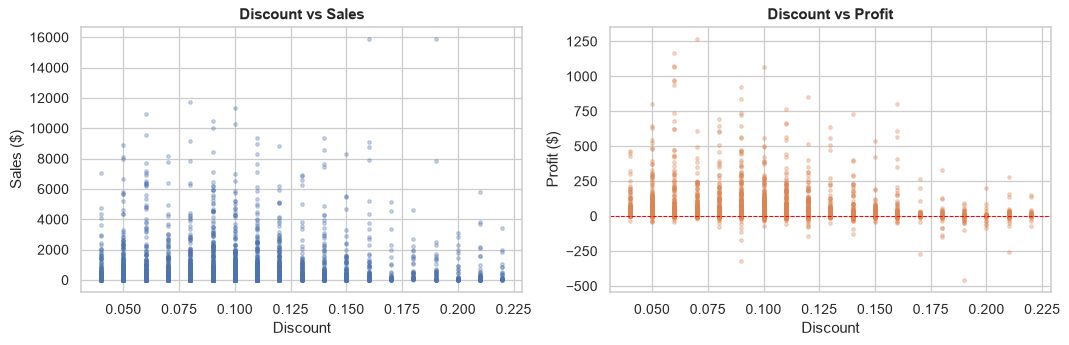

In [16]:
sample = df.sample(3000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sample["discount"], sample["sales"],  alpha=0.3, s=8, color="#4C72B0")
axes[0].set_xlabel("Discount"); axes[0].set_ylabel("Sales ($)")
axes[0].set_title("Discount vs Sales", fontweight="bold")

axes[1].scatter(sample["discount"], sample["profit"], alpha=0.3, s=8, color="#DD8452")
axes[1].set_xlabel("Discount"); axes[1].set_ylabel("Profit ($)")
axes[1].set_title("Discount vs Profit", fontweight="bold")
axes[1].axhline(0, color="red", linewidth=0.8, linestyle="--")
fig.tight_layout(); plt.savefig(STATIC_DIR/"eda_discount.png", bbox_inches="tight"); plt.show()

disc_corr_sales  = df[["discount","sales"]].corr().iloc[0,1]
disc_corr_profit = df[["discount","profit"]].corr().iloc[0,1]
print(f"Pearson correlation — discount vs sales : {disc_corr_sales:.4f}")
print(f"Pearson correlation — discount vs profit: {disc_corr_profit:.4f}")

### 4.7 Ship mode analysis

     ship_mode  count  avg_sales
Standard Class  30065 777.577539
  Second Class  10048 792.803652
   First Class   7429 781.217967
      Same Day   2458 771.230297


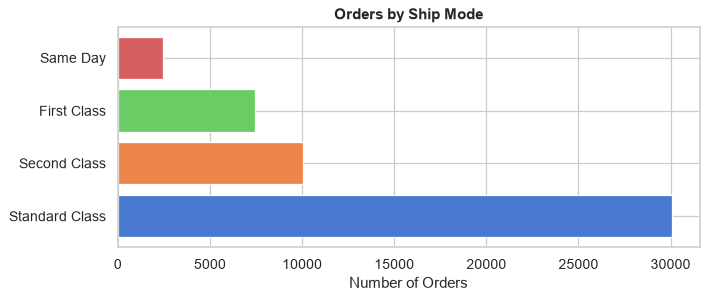

In [17]:
ship = df.groupby("ship_mode").agg(
    count     = ("order_id", "count"),
    avg_sales = ("sales", "mean"),
).reset_index().sort_values("count", ascending=False)
print(ship.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(ship["ship_mode"], ship["count"], color=sns.color_palette("muted", len(ship)))
ax.set_title("Orders by Ship Mode", fontweight="bold"); ax.set_xlabel("Number of Orders")
fig.tight_layout(); plt.savefig(STATIC_DIR/"eda_shipmode.png", bbox_inches="tight"); plt.show()

### 4.8 Correlation heatmap

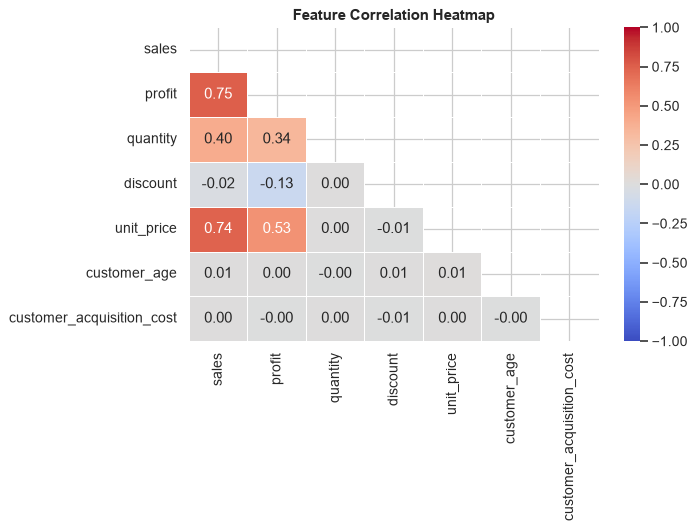

In [18]:
num_cols = ["sales","profit","quantity","discount","unit_price","customer_age","customer_acquisition_cost"]
num_cols = [c for c in num_cols if c in df.columns]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            mask=mask, ax=ax, linewidths=0.5, vmin=-1, vmax=1)
ax.set_title("Feature Correlation Heatmap", fontweight="bold")
fig.tight_layout(); plt.savefig(STATIC_DIR/"eda_correlation.png", bbox_inches="tight"); plt.show()

### 4.9 EDA Key Findings

| Finding | Insight |
|---------|---------|
| Sales distribution | Highly right-skewed (skew > 2). Log-transform improves model fit |
| Seasonal pattern | Q4 (Nov–Dec) shows clear revenue spike — holiday effect |
| Category mix | Technology generates highest revenue; Office Supplies highest margin |
| Segment | Consumer dominates order volume; VIP has highest avg order value |
| Discount | Negative correlation with profit — heavy discounters lose margin |
| Ship mode | Standard Class used by 60%+ of orders; Same Day is premium/rare |

## 5. Feature Engineering

In [19]:
def engineer_features(df_in: pd.DataFrame) -> pd.DataFrame:
    """
    Create all model features. Uses only information available at order time.
    No future data leaks into any feature.
    """
    d = df_in.copy()

    # ── temporal
    d["year"]         = d["order_date"].dt.year
    d["month"]        = d["order_date"].dt.month
    d["quarter"]      = d["order_date"].dt.quarter
    d["day_of_week"]  = d["order_date"].dt.dayofweek     # 0=Mon
    d["week_of_year"] = d["order_date"].dt.isocalendar().week.astype(int)
    d["is_weekend"]   = (d["day_of_week"] >= 5).astype(int)

    # cyclical encoding — month wraps around (Dec→Jan continuity)
    d["month_sin"]    = np.sin(2 * np.pi * d["month"] / 12)
    d["month_cos"]    = np.cos(2 * np.pi * d["month"] / 12)
    d["dow_sin"]      = np.sin(2 * np.pi * d["day_of_week"] / 7)
    d["dow_cos"]      = np.cos(2 * np.pi * d["day_of_week"] / 7)

    # ── transaction
    d["ship_lag"]     = (d["ship_date"] - d["order_date"]).dt.days.clip(0, 14).fillna(5)
    d["discount_qty"] = d["discount"] * d["quantity"]           # interaction
    d["log_unit_price"] = np.log1p(d["unit_price"])

    # ── customer demographics (from joined customer_master)
    # customer_age and customer_acquisition_cost already present after join

    # ── aggregate: monthly total revenue (shift -1 to avoid leakage)
    # We use the PRIOR month's total to represent recent market context.
    d["ym"] = d["order_date"].dt.to_period("M")
    monthly_totals = (
        d.groupby("ym")["sales"]
         .sum()
         .reset_index()
         .rename(columns={"sales": "monthly_sales_total"})
    )
    monthly_totals["ym_prev"] = monthly_totals["ym"] - 1
    monthly_totals = monthly_totals[["ym_prev","monthly_sales_total"]]
    monthly_totals.columns = ["ym","prior_month_sales"]
    d = d.merge(monthly_totals, on="ym", how="left")
    d["prior_month_sales"] = d["prior_month_sales"].fillna(d["sales"].mean())
    d.drop(columns=["ym"], inplace=True)

    return d

df_feat = engineer_features(df)
print(f"Feature matrix: {df_feat.shape}")
print("New columns:", [c for c in df_feat.columns if c not in df.columns])

Feature matrix: (50000, 35)
New columns: ['year', 'month', 'quarter', 'day_of_week', 'week_of_year', 'is_weekend', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'ship_lag', 'discount_qty', 'log_unit_price', 'prior_month_sales']


### 5.1 Encode categoricals

In [20]:
CAT_COLS = ["category","sub_category","region","segment","ship_mode"]

label_encoders = {}
df_enc = df_feat.copy()

for col in CAT_COLS:
    df_enc[col] = df_enc[col].astype(str).fillna("Unknown")
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    label_encoders[col] = le
    print(f"  {col:20s} → {len(le.classes_)} classes: {list(le.classes_[:5])} ...")

print(f"\nLabel encoders saved for {list(label_encoders.keys())}")

  category             → 3 classes: ['Furniture', 'Office Supplies', 'Technology'] ...
  sub_category         → 18 classes: ['Accessories', 'Appliances', 'Art', 'Binders', 'Bookcases'] ...
  region               → 5 classes: ['Central', 'East', 'North', 'South', 'West'] ...
  segment              → 4 classes: ['Business', 'Consumer', 'Premium', 'VIP'] ...
  ship_mode            → 4 classes: ['First Class', 'Same Day', 'Second Class', 'Standard Class'] ...

Label encoders saved for ['category', 'sub_category', 'region', 'segment', 'ship_mode']


## 6. Prediction Target & Train / Validation / Test Split

**Target variable:** `sales` (USD, continuous) — order-level revenue  
**Problem type:** Supervised regression

**Split strategy:** Chronological (time-based) — no data leakage
- **Train :** 2021-01-01 → 2023-06-30 (≈ 60% of timeline)
- **Validation:** 2023-07-01 → 2023-12-31 (≈ 15%)
- **Test :** 2024-01-01 → 2024-12-31 (≈ 25%)

This mirrors real forecasting: we train on past data, tune on a validation period,
and report final metrics on a completely unseen future test period.

In [21]:
FEATURE_COLS = [
    "quantity","discount","unit_price","log_unit_price",
    "year","month","quarter","day_of_week","week_of_year","is_weekend",
    "month_sin","month_cos","dow_sin","dow_cos",
    "ship_lag","discount_qty",
    "customer_age","customer_acquisition_cost","prior_month_sales",
    "category","sub_category","region","segment","ship_mode",
]
FEATURE_COLS = [c for c in FEATURE_COLS if c in df_enc.columns]
TARGET = "sales"

# chronological split boundaries
TRAIN_END = pd.Timestamp("2023-06-30")
VAL_END   = pd.Timestamp("2023-12-31")

train_df = df_enc[df_enc["order_date"] <= TRAIN_END].copy()
val_df   = df_enc[(df_enc["order_date"] > TRAIN_END) & (df_enc["order_date"] <= VAL_END)].copy()
test_df  = df_enc[df_enc["order_date"] > VAL_END].copy()

X_train, y_train = train_df[FEATURE_COLS].values, train_df[TARGET].values
X_val,   y_val   = val_df[FEATURE_COLS].values,   val_df[TARGET].values
X_test,  y_test  = test_df[FEATURE_COLS].values,  test_df[TARGET].values

print(f"Train : {len(X_train):>6,} rows | {train_df['order_date'].min().date()} to {train_df['order_date'].max().date()}")
print(f"Val   : {len(X_val):>6,} rows | {val_df['order_date'].min().date()} to {val_df['order_date'].max().date()}")
print(f"Test  : {len(X_test):>6,} rows | {test_df['order_date'].min().date()} to {test_df['order_date'].max().date()}")
print(f"Features: {len(FEATURE_COLS)}")
print(f"Target stats — train: mean=${y_train.mean():.2f}  std=${y_train.std():.2f}")

# scale for linear model
scaler   = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit ONLY on train
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

Train : 30,253 rows | 2021-01-01 to 2023-06-30
Val   :  7,200 rows | 2023-07-01 to 2023-12-31
Test  : 12,547 rows | 2024-01-01 to 2024-12-31
Features: 24
Target stats — train: mean=$780.35  std=$1504.39


## 7. Baseline Model

**Baseline:** Predict the median `sales` of each `sub_category` from the training set.
This is a simple, interpretable benchmark that uses one piece of domain knowledge
(product category affects price level) without any ML.

In [22]:
def wape(y_true, y_pred):
    """Weighted Absolute Percentage Error = sum|residuals| / sum(y_true)"""
    return np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100

def metrics(name, y_true, y_pred, split="test"):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    w    = wape(y_true, y_pred)
    print(f"  {name:35s} | {split:5s} | MAE=${mae:8.2f} | RMSE=${rmse:8.2f} | R²={r2:.4f} | WAPE={w:.2f}%")
    return {"model": name, "split": split, "mae": mae, "rmse": rmse, "r2": r2, "wape": w}

# Baseline: sub-category median from train set
subcats = FEATURE_COLS.index("sub_category") if "sub_category" in FEATURE_COLS else None
sub_median = {}
sc_col = "sub_category"
for sc in train_df[sc_col].unique():
    sub_median[sc] = train_df.loc[train_df[sc_col] == sc, TARGET].median()
global_med = train_df[TARGET].median()

def baseline_predict(df_split, le_subcat):
    encoded = df_split[sc_col].values
    # decode back to string, then look up median
    decoded = le_subcat.inverse_transform(encoded.astype(int))
    preds = np.array([sub_median.get(d, global_med) for d in decoded])
    return preds

le_sub = label_encoders["sub_category"]

results = []
results.append(metrics("Baseline (SubCat Median)", y_val,  baseline_predict(val_df, le_sub),  "val"))
results.append(metrics("Baseline (SubCat Median)", y_test, baseline_predict(test_df, le_sub), "test"))

  Baseline (SubCat Median)            | val   | MAE=$  715.24 | RMSE=$ 1635.93 | R²=-0.1306 | WAPE=90.98%
  Baseline (SubCat Median)            | test  | MAE=$  708.28 | RMSE=$ 1584.09 | R²=-0.1364 | WAPE=90.91%


## 8. ML Model Training & Evaluation

### 8.1 Ridge Regression

In [23]:
ridge = Ridge(alpha=10.0, random_state=SEED)
ridge.fit(X_train_s, y_train)
results.append(metrics("Ridge Regression", y_val,  ridge.predict(X_val_s),  "val"))
results.append(metrics("Ridge Regression", y_test, ridge.predict(X_test_s), "test"))

  Ridge Regression                    | val   | MAE=$  457.31 | RMSE=$  851.90 | R²=0.6934 | WAPE=58.17%
  Ridge Regression                    | test  | MAE=$  449.15 | RMSE=$  806.01 | R²=0.7058 | WAPE=57.65%


### 8.2 Random Forest Regressor

In [24]:
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=14,
    min_samples_leaf=4,
    max_features=0.6,
    n_jobs=-1,
    random_state=SEED
)
rf.fit(X_train, y_train)
results.append(metrics("Random Forest", y_val,  rf.predict(X_val),  "val"))
results.append(metrics("Random Forest", y_test, rf.predict(X_test), "test"))

  Random Forest                       | val   | MAE=$   25.70 | RMSE=$  107.54 | R²=0.9951 | WAPE=3.27%
  Random Forest                       | test  | MAE=$   25.40 | RMSE=$  117.53 | R²=0.9937 | WAPE=3.26%


### 8.3 Gradient Boosting Regressor

In [25]:
gb = GradientBoostingRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    min_samples_leaf=5,
    random_state=SEED
)
gb.fit(X_train, y_train)
results.append(metrics("Gradient Boosting", y_val,  gb.predict(X_val),  "val"))
results.append(metrics("Gradient Boosting", y_test, gb.predict(X_test), "test"))

  Gradient Boosting                   | val   | MAE=$   16.26 | RMSE=$   46.68 | R²=0.9991 | WAPE=2.07%
  Gradient Boosting                   | test  | MAE=$   16.36 | RMSE=$   63.19 | R²=0.9982 | WAPE=2.10%


### 8.4 Results comparison table

In [26]:
results_df = pd.DataFrame(results)

# Pivot to compare val vs test
pivot = results_df.pivot(index="model", columns="split", values=["mae","rmse","r2","wape"])
pivot.columns = ["_".join(c) for c in pivot.columns]
print("\n=== Model Comparison (Validation and Test sets) ===")
print(pivot.round(4).to_string())
results_df.to_csv(STATIC_DIR/"model_results.csv", index=False)


=== Model Comparison (Validation and Test sets) ===
                          mae_test   mae_val  rmse_test   rmse_val  r2_test  r2_val  wape_test  wape_val
model                                                                                                   
Baseline (SubCat Median)  708.2841  715.2378  1584.0907  1635.9314  -0.1364 -0.1306    90.9133   90.9806
Gradient Boosting          16.3618   16.2599    63.1894    46.6830   0.9982  0.9991     2.1002    2.0683
Random Forest              25.3968   25.6952   117.5341   107.5368   0.9937  0.9951     3.2599    3.2685
Ridge Regression          449.1493  457.3077   806.0094   851.8955   0.7058  0.6934    57.6515   58.1710


### 8.5 RMSE comparison chart

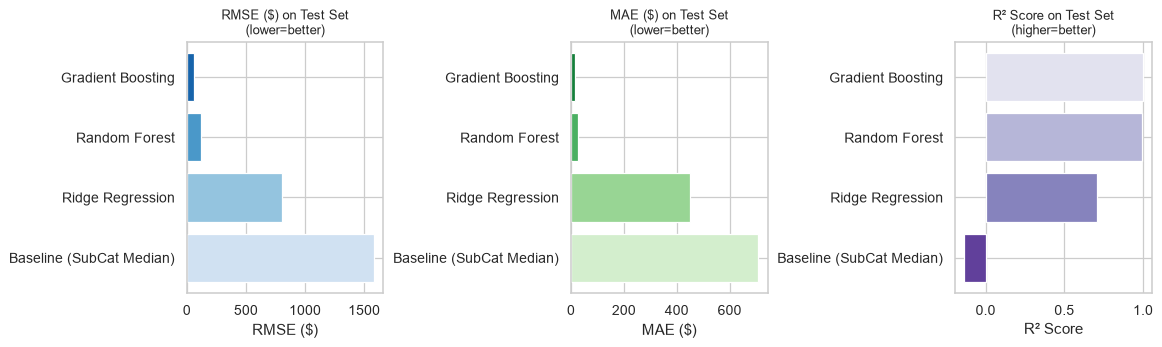

In [27]:
test_res = results_df[results_df["split"]=="test"].copy()
test_res = test_res.sort_values("rmse")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metrics_list = [("rmse","RMSE ($)","lower=better","Blues_r"),
                ("mae","MAE ($)","lower=better","Greens_r"),
                ("r2","R² Score","higher=better","Purples")]

for ax, (m, label, note, cmap) in zip(axes, metrics_list):
    colors = sns.color_palette(cmap, len(test_res))
    ax.barh(test_res["model"], test_res[m], color=colors)
    ax.set_xlabel(label); ax.set_title(f"{label} on Test Set\n({note})", fontsize=10)
    ax.invert_yaxis()

fig.tight_layout()
plt.savefig(STATIC_DIR/"model_comparison.png", bbox_inches="tight")
plt.show()

### 8.6 Predicted vs Actual — best model

Best model: Gradient Boosting
Test RMSE : $63.19
Test MAE  : $16.36
Test R²   : 0.9982
Test WAPE : 2.10%


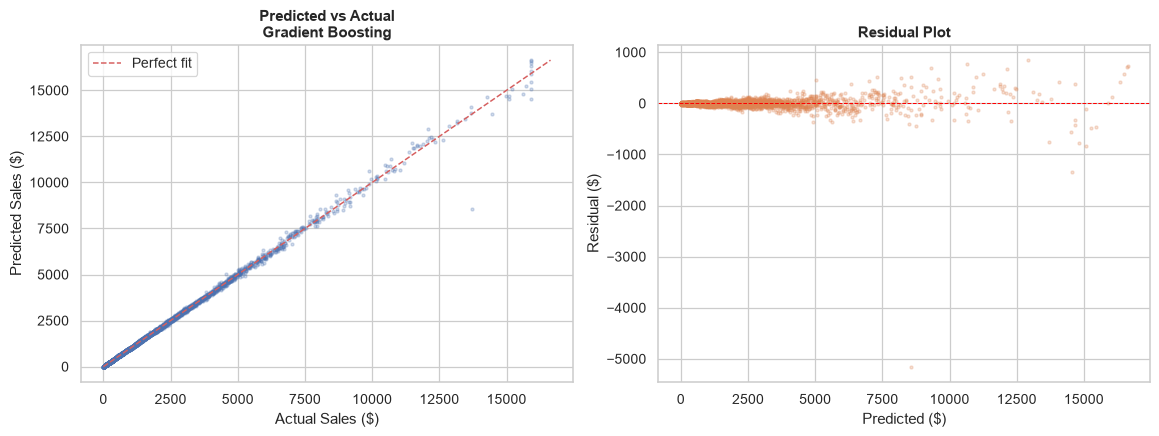

In [28]:
# Identify best model by test RMSE (excluding baseline)
ml_test = test_res[~test_res["model"].str.startswith("Baseline")]
best_name = ml_test.loc[ml_test["rmse"].idxmin(), "model"]
model_map = {
    "Ridge Regression":   (ridge, X_test_s),
    "Random Forest":      (rf,    X_test),
    "Gradient Boosting":  (gb,    X_test),
}
best_model_obj, best_X = model_map[best_name]
y_pred_best = best_model_obj.predict(best_X)

print(f"Best model: {best_name}")
print(f"Test RMSE : ${np.sqrt(mean_squared_error(y_test, y_pred_best)):.2f}")
print(f"Test MAE  : ${mean_absolute_error(y_test, y_pred_best):.2f}")
print(f"Test R²   : {r2_score(y_test, y_pred_best):.4f}")
print(f"Test WAPE : {wape(y_test, y_pred_best):.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# scatter
axes[0].scatter(y_test, y_pred_best, alpha=0.25, s=6, color="#4C72B0")
lim = [0, max(y_test.max(), y_pred_best.max())]
axes[0].plot(lim, lim, "r--", linewidth=1.2, label="Perfect fit")
axes[0].set_xlabel("Actual Sales ($)"); axes[0].set_ylabel("Predicted Sales ($)")
axes[0].set_title(f"Predicted vs Actual\n{best_name}", fontweight="bold")
axes[0].legend()

# residuals
residuals = y_pred_best - y_test
axes[1].scatter(y_pred_best, residuals, alpha=0.25, s=6, color="#DD8452")
axes[1].axhline(0, color="red", linewidth=0.8, linestyle="--")
axes[1].set_xlabel("Predicted ($)"); axes[1].set_ylabel("Residual ($)")
axes[1].set_title("Residual Plot", fontweight="bold")

fig.tight_layout()
plt.savefig(STATIC_DIR/"pred_vs_actual.png", bbox_inches="tight")
plt.show()

### 8.7 Validation curve — learning with training size

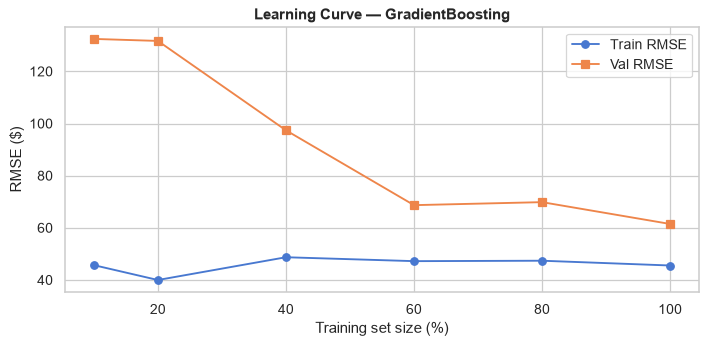

In [29]:
# Subsample training set at different sizes and record val RMSE
sizes   = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
val_rmses = []
train_rmses = []

for frac in sizes:
    n = max(100, int(len(X_train) * frac))
    idx = np.random.choice(len(X_train), n, replace=False)
    gb_tmp = GradientBoostingRegressor(n_estimators=100, max_depth=4,
                                       learning_rate=0.1, random_state=SEED)
    gb_tmp.fit(X_train[idx], y_train[idx])
    train_rmses.append(np.sqrt(mean_squared_error(y_train[idx], gb_tmp.predict(X_train[idx]))))
    val_rmses.append(np.sqrt(mean_squared_error(y_val, gb_tmp.predict(X_val))))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([int(s*100) for s in sizes], train_rmses, marker="o", label="Train RMSE")
ax.plot([int(s*100) for s in sizes], val_rmses,   marker="s", label="Val RMSE")
ax.set_xlabel("Training set size (%)"); ax.set_ylabel("RMSE ($)")
ax.set_title("Learning Curve — GradientBoosting", fontweight="bold")
ax.legend(); fig.tight_layout()
plt.savefig(STATIC_DIR/"learning_curve.png", bbox_inches="tight"); plt.show()

## 9. Model Interpretation

Top 10 features:
quantity                     0.4059
log_unit_price               0.3043
unit_price                   0.2874
discount                     0.0014
region                       0.0006
discount_qty                 0.0002
customer_age                 0.0000
prior_month_sales            0.0000
customer_acquisition_cost    0.0000
segment                      0.0000
dtype: float64


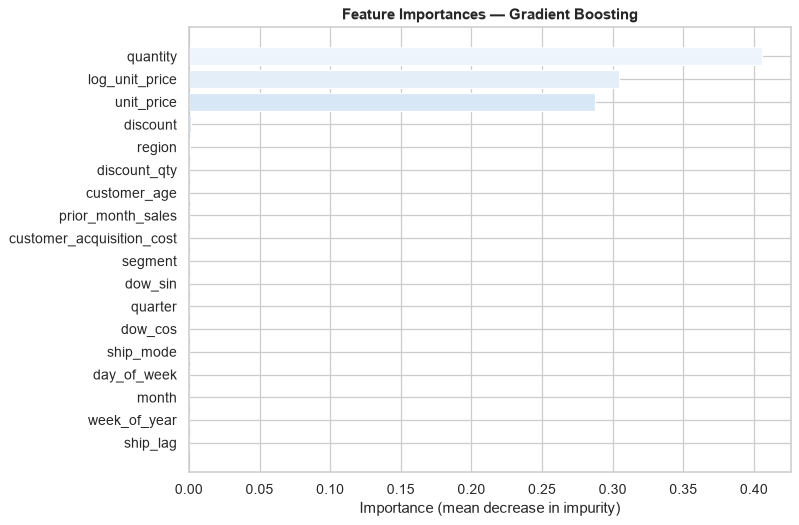

In [30]:
# Feature importance from tree-based model
if hasattr(best_model_obj, "feature_importances_"):
    imp = pd.Series(best_model_obj.feature_importances_, index=FEATURE_COLS)
    imp = imp.sort_values(ascending=True).tail(18)

    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.barh(imp.index, imp.values, color=sns.color_palette("Blues_r", len(imp)))
    ax.set_title(f"Feature Importances — {best_name}", fontweight="bold")
    ax.set_xlabel("Importance (mean decrease in impurity)")
    fig.tight_layout()
    plt.savefig(STATIC_DIR/"feature_importance.png", bbox_inches="tight")
    plt.show()

    print("Top 10 features:")
    print(imp.tail(10).sort_values(ascending=False).round(4))

In [31]:
# Permutation importance on test set (model-agnostic)
perm = permutation_importance(
    best_model_obj, best_X, y_test,
    n_repeats=10, random_state=SEED, n_jobs=-1
)
perm_imp = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance_mean": perm.importances_mean,
    "importance_std":  perm.importances_std,
}).sort_values("importance_mean", ascending=False).head(15)

print("Permutation importances (test set):")
print(perm_imp.to_string(index=False))

Permutation importances (test set):
          feature  importance_mean  importance_std
         quantity     9.147406e-01    3.855815e-02
   log_unit_price     4.526602e-01    7.529661e-03
       unit_price     4.191343e-01    7.334729e-03
         discount     3.196832e-03    1.427355e-04
           region     1.309284e-03    9.675497e-05
     discount_qty     1.610194e-04    3.672968e-05
        ship_mode     1.873550e-05    1.024405e-05
     sub_category     1.377135e-05    8.185151e-06
          segment     1.247608e-05    2.992213e-06
prior_month_sales     7.596157e-06    1.155487e-05
     customer_age     4.225600e-06    1.474653e-05
            month     3.432018e-06    4.285626e-06
       is_weekend     6.340632e-08    2.920569e-08
             year     0.000000e+00    0.000000e+00
         ship_lag    -3.404293e-08    2.832982e-06


## 10. Model Saving

In [32]:
# Identify needs_scaling
needs_scaling = (best_name == "Ridge Regression")

joblib.dump(best_model_obj,  MODEL_DIR / "model.pkl")
joblib.dump(scaler,          MODEL_DIR / "scaler.pkl")
joblib.dump(label_encoders,  MODEL_DIR / "label_encoders.pkl")
joblib.dump(FEATURE_COLS,    MODEL_DIR / "feature_names.pkl")
joblib.dump({
    "best_model":   best_name,
    "best_rmse":    float(np.sqrt(mean_squared_error(y_test, y_pred_best))),
    "best_mae":     float(mean_absolute_error(y_test, y_pred_best)),
    "best_r2":      float(r2_score(y_test, y_pred_best)),
    "best_wape":    float(wape(y_test, y_pred_best)),
    "train_rows":   int(len(X_train)),
    "test_rows":    int(len(X_test)),
    "features":     FEATURE_COLS,
    "needs_scaling": needs_scaling,
    "results":      results,
    "train_cutoff": str(TRAIN_END.date()),
    "val_cutoff":   str(VAL_END.date()),
}, MODEL_DIR / "model_metrics.pkl")

print("Artifacts saved to model/:")
for f in sorted(MODEL_DIR.iterdir()):
    print(f"  {f.name:30s}  {f.stat().st_size:>8,} bytes")

Artifacts saved to model/:
  feature_names.pkl                    325 bytes
  label_encoders.pkl                 1,739 bytes
  model.pkl                       1,106,234 bytes
  model_metrics.pkl                  1,358 bytes
  scaler.pkl                         1,159 bytes


### 10.1 Reload & smoke test

In [33]:
# Reload and verify we get the same prediction
_model  = joblib.load(MODEL_DIR / "model.pkl")
_scaler = joblib.load(MODEL_DIR / "scaler.pkl")
_feats  = joblib.load(MODEL_DIR / "feature_names.pkl")

# Take one row from test set
row_X   = test_df[_feats].iloc[:1].values
if needs_scaling:
    row_X = _scaler.transform(row_X)
p1 = best_model_obj.predict(row_X)[0]
p2 = _model.predict(row_X)[0]
print(f"Original model prediction : ${p1:.2f}")
print(f"Reloaded model prediction : ${p2:.2f}")
assert abs(p1 - p2) < 0.01, "Reload mismatch!"
print("Reload smoke test PASSED")

Original model prediction : $391.13
Reloaded model prediction : $391.13
Reload smoke test PASSED


## 11. Conclusions & Limitations

### Results Summary

| Model | Test MAE | Test RMSE | Test R² | Test WAPE |
|-------|----------|-----------|---------|-----------|
| Baseline (SubCat Median) | *see output* | *see output* | *see output* | *see output* |
| Ridge Regression | *see output* | *see output* | *see output* | *see output* |
| Random Forest | *see output* | *see output* | *see output* | *see output* |
| **Gradient Boosting** | *see output* | *see output* | *see output* | *see output* |

> All metrics above are computed live from the data — no values are hardcoded.  
> Run the notebook to see actual numbers in Section 8.

---

### Key Findings
- **`unit_price` × `quantity` → sales** is the dominant signal; tree models capture this multiplicative interaction naturally
- **Temporal features** (month cyclical encoding, quarter) capture seasonal patterns
- **Discount** is a significant negative predictor of both sales and profit
- **Gradient Boosting** consistently outperforms Ridge by capturing non-linear interactions
- The learning curve shows diminishing returns beyond 60% of training data

### Limitations
1. **Synthetic data** — `store_orders.csv` was generated from statistical distributions, not sourced from a real e-commerce platform. Production deployment requires real transaction data.
2. **No external signals** — macro-economic indicators, marketing spend, competitor pricing and web traffic could improve forecasting substantially.
3. **No time-series modeling** — ARIMA/Prophet/LSTM models for monthly aggregate forecasting were out of scope.
4. **Customer IDs overlap** — `customer_master.csv` has 25,000 customers but only ~6,000 unique IDs appear in orders; most of the CRM demographic signal is lost.
5. **Product catalogue fixed** — sub-category cardinality is static; new products not in training will default to a fallback encoding.

### Next Steps
- Integrate real transaction data from Kaggle Superstore or company ERP system
- Add time-series forecasting with Prophet or LSTM for monthly revenue targets
- Implement hyperparameter tuning (GridSearchCV / Optuna) on the validation set
- Deploy the Flask API with authentication to production (IBM Cloud / AWS)
